# 可复现实验模板

[返回总目录](README.md) · [排错手册](DEBUGGING_PLAYBOOK.md)

这个模板演示 RL 实验的最小可信单位：**配置、多个随机种子、原始曲线、聚合统计、失败记录**。示例使用二臂 bandit，方法可以原样迁移到 DQN/PPO。


In [1]:
from dataclasses import asdict, dataclass
import random
import numpy as np
import matplotlib.pyplot as plt

@dataclass(frozen=True)
class Config:
    episodes: int = 400
    learning_rate: float = 0.08
    baseline_rate: float = 0.05
    seeds: tuple = (0, 1, 2, 3, 4)

config = Config()
print(asdict(config))


{'episodes': 400, 'learning_rate': 0.08, 'baseline_rate': 0.05, 'seeds': (0, 1, 2, 3, 4)}


## 1. 单次运行必须是纯函数式边界

输入配置和 seed，返回逐 episode 指标。不要让上一轮模型、全局 RNG 或 replay buffer 泄漏到下一轮。


In [2]:
def run_one(seed, cfg):
    random.seed(seed)
    rng = np.random.default_rng(seed)
    theta, baseline = 0.0, 0.0
    rewards = []
    for _ in range(cfg.episodes):
        p = 1 / (1 + np.exp(-theta))
        action = float(rng.random() < p)
        reward = float(rng.random() < (0.25 if action == 0 else 0.75))
        advantage = reward - baseline
        baseline += cfg.baseline_rate * advantage
        theta += cfg.learning_rate * advantage * (action - p)
        rewards.append(reward)
    return np.asarray(rewards)

runs = np.stack([run_one(seed, config) for seed in config.seeds])
assert runs.shape == (len(config.seeds), config.episodes)
print("raw result shape:", runs.shape)


raw result shape: (5, 400)


## 2. 先聚合每个 seed，再跨 seed 统计

不要把所有 episode 当成独立样本计算置信区间；实验重复单位是 seed。下面展示均值和 95% 近似置信带。


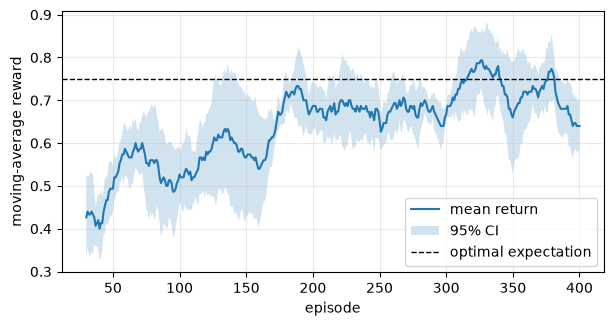

final per-seed means: [0.68 0.64 0.8  0.72 0.68]


In [3]:
window = 30
smoothed = np.stack([
    np.convolve(run, np.ones(window) / window, mode="valid") for run in runs
])
mean = smoothed.mean(axis=0)
sem = smoothed.std(axis=0, ddof=1) / np.sqrt(len(config.seeds))
x = np.arange(window, config.episodes + 1)

plt.figure(figsize=(7, 3.4))
plt.plot(x, mean, label="mean return")
plt.fill_between(x, mean - 1.96*sem, mean + 1.96*sem, alpha=.2, label="95% CI")
plt.axhline(.75, color="black", linestyle="--", linewidth=1, label="optimal expectation")
plt.xlabel("episode"); plt.ylabel("moving-average reward")
plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
print("final per-seed means:", np.round(runs[:, -50:].mean(axis=1), 3))


## 3. 调参记录表

| run id | 唯一改动 | 事前假设 | 主要指标 | 结果 | 下一步 |
|---|---|---|---|---|---|
| baseline | 无 | 建立可复现基线 | return / entropy | 待填写 | — |
| lr-low | learning rate ↓ | 更稳但更慢 | return / KL | 待填写 | 接受或否定假设 |
| lr-high | learning rate ↑ | 更快但方差大 | return / KL | 待填写 | 检查崩溃种子 |

正式项目还应保存：代码版本、依赖版本、设备、环境版本、总环境步数、wall-clock、最佳与最后 checkpoint。


## 4. 最小报告结构

1. **问题与假设：**为什么做这次实验？
2. **不可变条件：**哪些配置、预算和评估规则保持一致？
3. **结果：**所有 seed 的聚合曲线和最终指标表。
4. **失败：**至少记录一个无效尝试，以及它排除了什么解释。
5. **结论边界：**结论适用于哪些环境、预算和种子？

如果报告中只有最好曲线、没有 seed、没有评估协议，它只能算演示，不能算可信实验。
